# Formativa 1 · Tiempo de navegación en productos y compra

**Grupo 9: Guillermo Osorio Zamora y Karla Patricia Pizarro Correa**  
Estadística Computacional · MCDI501 · Docente Jean Maidana

**Pregunta:** ¿El tiempo dedicado a páginas de productos difiere entre las sesiones que terminan en compra y las que no?

Analizamos la relación entre dos grupos de sesiones del conjunto de datos Online Shoppers Purchasing Intention. Para comparar ambos grupos, nos enfocaremos en las **medias**, evaluando la diferencia en el tiempo promedio entre las sesiones que terminaron en compra y las que no. Además, utilizaremos la mediana y gráficos para describir mejor cómo se distribuyen los datos.

**Objetivo:** comparar los tiempos de ambos grupos, describir sus diferencias y aplicar los intervalos de confianza y la prueba de hipótesis enseñados en la semana 1.

Una fila representa una **sesión de navegación**. Compararemos la media **con compra menos sin compra**. Este análisis muestra una relación entre variables; no demuestra que pasar más tiempo provoque una compra.

## Antes de comenzar

Abrir este archivo dentro de `Formativa_1` con el kernel **Python (Estadistica Computacional)**. Las rutas se leen desde esta carpeta; no es necesario escribir una ruta personal de Windows.

El CSV original debe estar en `datos_originales` y la versión preparada en `datos_trabajo`. Si todavía falta esta última, ejecutar primero `00_preparar_datos.ipynb`. En el equipo de Guillermo ya existe: **vamos a reutilizarla**.

Ejecutar las celdas de arriba hacia abajo con **Shift + Enter**. Para comprobar todo desde cero, usar **Restart Kernel and Run All Cells**. Leer las explicaciones antes de pasar al paso siguiente.

Seguimos el orden de `f2_s01_tutorial_workflow.ipynb`; los intervalos y Welch corresponden a los tutoriales `python`, `suite` y `notebook` de la semana 1.

## Paso 1 Importar las bibliotecas

`pandas` permite trabajar con tablas; `numpy`, hacer cálculos; `matplotlib`, crear gráficos; y `scipy.stats`, calcular intervalos y pruebas estadísticas. Los nombres cortos `pd`, `np`, `plt` y `stats` son los mismos que usamos en las clases.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## Paso 2 Abrir y conocer el dataset original

`read_csv()` abre la tabla. `float_precision="round_trip"` conserva la precisión de los decimales guardados; es una opción de lectura, no un cálculo estadístico. `head()` muestra las primeras cinco filas.

In [2]:
df_original = pd.read_csv(
    "datos_originales/online_shoppers_intention.csv",
    float_precision="round_trip"
)
df_original.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
print("Filas y columnas:", df_original.shape)
df_original.info()

Filas y columnas: (12330, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64

Hay **12.330 filas y 18 columnas**. En `info()`, `int64` significa enteros, `float64` números con decimales, `object` contiene texto en este archivo y `bool` indica verdadero o falso. El tipo guardado no determina por sí solo el tipo estadístico: un código de región puede ser un número y seguir siendo una categoría.

### Ficha de las variables

| Variable | Qué representa | Tipo estadístico |
|---|---|---|
| Administrative | Cantidad de páginas administrativas visitadas | Cuantitativa discreta |
| Administrative_Duration | Tiempo en esas páginas, en segundos | Cuantitativa continua |
| Informational | Cantidad de páginas informativas visitadas | Cuantitativa discreta |
| Informational_Duration | Tiempo en esas páginas, en segundos | Cuantitativa continua |
| ProductRelated | Cantidad de páginas de productos visitadas | Cuantitativa discreta |
| ProductRelated_Duration | Tiempo total en páginas de productos, en segundos | Cuantitativa continua |
| BounceRates | Tasa de rebote de las páginas visitadas | Cuantitativa continua |
| ExitRates | Tasa de salida de las páginas visitadas | Cuantitativa continua |
| PageValues | Valor medio atribuido a las páginas visitadas | Cuantitativa continua |
| SpecialDay | Índice de proximidad a una fecha especial | Cuantitativa discreta |
| Month | Mes de la sesión | Categórica, mes del año |
| OperatingSystems | Código del sistema operativo | Categórica nominal |
| Browser | Código del navegador | Categórica nominal |
| Region | Código de la región | Categórica nominal |
| TrafficType | Código del origen del tráfico | Categórica nominal |
| VisitorType | Tipo de visitante | Categórica nominal |
| Weekend | Si la sesión ocurrió en fin de semana | Categórica binaria |
| Revenue | Si la sesión terminó en compra | Categórica binaria |

Usaremos principalmente **tiempo de productos** y **compra**. Una variable numérica y otra categórica se pueden comparar con estadísticos por grupo y un diagrama de cajas, como indica el material de clases.

`Revenue = True` significa compra y `False`, sin compra; no es un monto de dinero. `SpecialDay` toma 0; 0,2; 0,4; 0,6; 0,8; 1: es un índice, no días ni una probabilidad. Los meses tienen un orden de calendario que se repite cada año. Las unidades de duración se verificaron en la referencia [2], tabla 1.

## Paso 3 Revisar la calidad de los datos

`isna().sum()` cuenta los datos faltantes de cada columna. `duplicated().sum()` cuenta filas idénticas adicionales. Revisamos también tiempos negativos y tiempos iguales a cero.

In [4]:
df_original.isna().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [5]:
print("Filas idénticas adicionales:", df_original.duplicated().sum())
print("Tiempos negativos:", (df_original["ProductRelated_Duration"] < 0).sum())
print("Tiempos iguales a cero:", (df_original["ProductRelated_Duration"] == 0).sum())

Filas idénticas adicionales: 125
Tiempos negativos: 0
Tiempos iguales a cero: 755


El original no tiene faltantes. Hay **125 filas idénticas adicionales**, **0 tiempos negativos** y **755 tiempos iguales a cero**. Conservamos las filas idénticas porque no contamos con un identificador para confirmar que sean la misma sesión. También conservamos los ceros y los tiempos muy altos: no basta con que un valor sea llamativo para declararlo un error.

## Paso 4 Abrir la versión de trabajo

La guía de datasets exige crear faltantes artificiales cuando el original está completo. Se ocultó al azar el **10% de los tiempos de productos**, es decir, 1.233 valores, con semilla 42. La elección no usó el tiempo ni la compra; este mecanismo se llama **MCAR**, faltantes completamente al azar.

El notebook de preparación explica cómo se hizo y conserva los valores ocultados en otro archivo. Aquí solo abrimos la versión ya guardada. No volvemos a sortear filas ni rellenamos los faltantes.

In [6]:
df = pd.read_csv(
    "datos_trabajo/online_shoppers_mcar.csv",
    float_precision="round_trip"
)
df.isna().sum()

Administrative                0
Administrative_Duration       0
Informational                 0
Informational_Duration        0
ProductRelated                0
ProductRelated_Duration    1233
BounceRates                   0
ExitRates                     0
PageValues                    0
SpecialDay                    0
Month                         0
OperatingSystems              0
Browser                       0
Region                        0
TrafficType                   0
VisitorType                   0
Weekend                       0
Revenue                       0
dtype: int64

## Paso 5 Contar las sesiones de cada grupo

`value_counts()` cuenta cuántas veces aparece cada categoría. Con `normalize=True` obtenemos proporciones; multiplicar por 100 las convierte en porcentajes. Estos conteos usan **todas las sesiones**, incluso si falta su duración.

In [7]:
print("Sesiones según compra:")
print(df["Revenue"].value_counts())
print("\nPorcentaje de sesiones:")
print(df["Revenue"].value_counts(normalize=True) * 100)

Sesiones según compra:
Revenue
False    10422
True      1908
Name: count, dtype: int64

Porcentaje de sesiones:
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


Podemos repetir las frecuencias para reconocer las otras categorías. El `for` recorre una lista de columnas y ejecuta las instrucciones indentadas para cada una. Los códigos de región, navegador y sistema operativo se cuentan como categorías.

In [8]:
columnas_categoricas = ["Month", "OperatingSystems", "Browser", "Region",
                         "TrafficType", "VisitorType", "Weekend"]
for columna in columnas_categoricas:
    print("\n", columna)
    print(df[columna].value_counts())


 Month
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

 OperatingSystems
OperatingSystems
2    6601
1    2585
3    2555
4     478
8      79
6      19
7       7
5       6
Name: count, dtype: int64

 Browser
Browser
2     7961
1     2462
4      736
5      467
6      174
10     163
8      135
3      105
13      61
7       49
12      10
11       6
9        1
Name: count, dtype: int64

 Region
Region
1    4780
3    2403
4    1182
2    1136
6     805
7     761
9     511
8     434
5     318
Name: count, dtype: int64

 TrafficType
TrafficType
2     3913
1     2451
3     2052
4     1069
13     738
10     450
6      444
8      343
5      260
11     247
20     198
9       42
7       40
15      38
19      17
14      13
18      10
16       3
12       1
17       1
Name: count, dtype: int64

 VisitorType
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other            

`groupby("Revenue")` separa los cálculos según compra. `size()` cuenta filas y `count()` cuenta duraciones disponibles. Su diferencia indica cuántas faltan.

In [9]:
resumen_grupos = pd.DataFrame()
resumen_grupos["Sesiones"] = df.groupby("Revenue").size()
resumen_grupos["Tiempo disponible"] = df.groupby("Revenue")["ProductRelated_Duration"].count()
resumen_grupos["Tiempo faltante"] = resumen_grupos["Sesiones"] - resumen_grupos["Tiempo disponible"]
resumen_grupos

,Sesiones,Tiempo disponible,Tiempo faltante
Revenue,,,
False,10422,9387,1035
True,1908,1710,198


Hay **1.908 sesiones con compra (15,47%)** y **10.422 sin compra (84,53%)**. Para comparar tiempos contamos con **1.710** y **9.387**, respectivamente. Los faltantes no quedaron exactamente en 10% dentro de cada grupo porque el sorteo se hizo sobre todas las filas.

## Paso 6 Preparar los dos grupos de tiempos

`dropna(subset=[...])` deja fuera solo las filas sin la duración que necesitamos. `.copy()` crea una tabla de análisis aparte: `df` conserva todas las sesiones.

Dividimos los segundos por 60 para leer los resultados en **minutos**. Esta conversión no cambia la comparación. Usamos nombres que indican claramente qué contiene cada grupo.

In [10]:
df_analisis = df.dropna(subset=["ProductRelated_Duration"]).copy()
df_analisis["Tiempo_minutos"] = df_analisis["ProductRelated_Duration"] / 60

tiempo_sin_compra = df_analisis.loc[df_analisis["Revenue"] == False, "Tiempo_minutos"]
tiempo_con_compra = df_analisis.loc[df_analisis["Revenue"] == True, "Tiempo_minutos"]

print("Sin compra:", len(tiempo_sin_compra))
print("Con compra:", len(tiempo_con_compra))
print("Total analizado:", len(df_analisis))

Sin compra: 9387
Con compra: 1710
Total analizado: 11097


## Paso 7 Describir los tiempos

`describe()` resume los datos. En la tabla: `count` es la cantidad; `mean`, la media; `std`, la desviación estándar muestral; `min` y `max`, los extremos. `50%` es la mediana; `25%` y `75%` son los cuartiles.

La **media** suma los tiempos y divide por la cantidad de sesiones. La **mediana** deja la mitad de los tiempos a cada lado. La **desviación estándar** describe cuánto se dispersan alrededor de la media; aquí también se mide en minutos.

In [11]:
resumen_tiempos = pd.DataFrame({
    "Sin compra": tiempo_sin_compra.describe(),
    "Con compra": tiempo_con_compra.describe()
})
resumen_tiempos.round(2)

,Sin compra,Con compra
count,9387.00,1710.00
mean,17.86,30.99
std,30.52,37.65
min,0.00,0.00
25%,2.50,9.03
50%,8.46,18.30
75%,22.07,37.68
max,1066.23,450.16


Para observar la separación del 50% central de los datos calculamos el **rango intercuartílico**, o RIC: tercer cuartil menos primer cuartil. Es menos sensible a los valores extremos que el rango completo.

In [12]:
ric_sin_compra = tiempo_sin_compra.quantile(0.75) - tiempo_sin_compra.quantile(0.25)
ric_con_compra = tiempo_con_compra.quantile(0.75) - tiempo_con_compra.quantile(0.25)
print(f"RIC sin compra: {ric_sin_compra:.2f} minutos")
print(f"RIC con compra: {ric_con_compra:.2f} minutos")

RIC sin compra: 19.57 minutos
RIC con compra: 28.65 minutos


La media es **17,86 minutos sin compra** y **30,99 con compra**. Las medianas son **8,46** y **18,30 minutos**. En ambos grupos la media supera a la mediana: algunos tiempos muy altos elevan el promedio. Por eso conviene mirar ambas medidas.

Como complemento, describimos la cantidad de páginas de productos. Aquí usamos `df`, porque esa variable no tiene faltantes. `agg()` aplica las funciones indicadas a cada grupo.

In [13]:
resumen_paginas = df.groupby("Revenue")["ProductRelated"].agg(["count", "mean", "median", "std"])
resumen_paginas.round(2)

,count,mean,median,std
Revenue,,,,
False,10422,28.71,16.0,40.74
True,1908,48.21,29.0,58.27


Las medias de páginas son **28,71 sin compra** y **48,21 con compra**. Esto sugiere que la cantidad de páginas puede ayudar a entender la diferencia de tiempo. Esta descripción no demuestra por qué se produjo la compra.

## Paso 8 Ver los datos en gráficos sencillos

### Histograma de los tiempos

Cada barra cuenta sesiones dentro de un tramo de cinco minutos. La figura muestra todos los tiempos a la izquierda y amplía la zona de 0 a 120 minutos a la derecha. `xlim()` solo cambia la vista; no elimina datos. Esta segunda vista permite distinguir las barras que quedan apretadas por los tiempos muy largos.

`subplot(1, 2, 1)` indica una fila, dos gráficos y la posición del primero. `savefig()` guarda una imagen local para el informe.

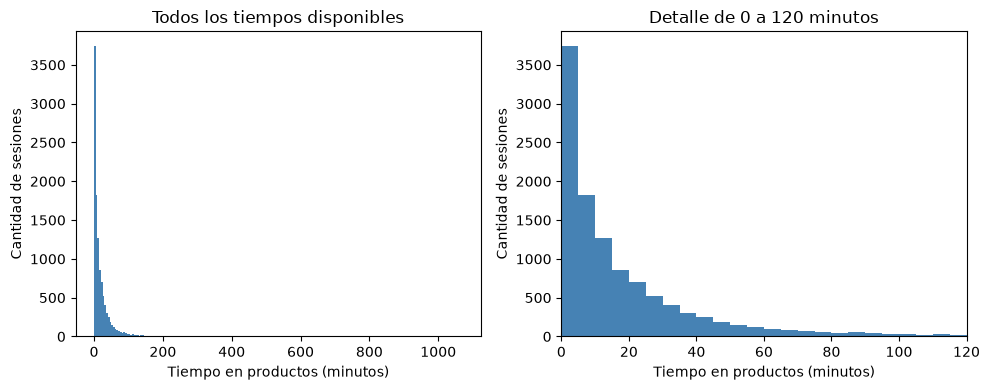

In [14]:
limites_barras = np.arange(0, df_analisis["Tiempo_minutos"].max() + 5, 5)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df_analisis["Tiempo_minutos"], bins=limites_barras, color="steelblue")
plt.title("Todos los tiempos disponibles")
plt.xlabel("Tiempo en productos (minutos)")
plt.ylabel("Cantidad de sesiones")

plt.subplot(1, 2, 2)
plt.hist(df_analisis["Tiempo_minutos"], bins=limites_barras, color="steelblue")
plt.xlim(0, 120)
plt.title("Detalle de 0 a 120 minutos")
plt.xlabel("Tiempo en productos (minutos)")
plt.ylabel("Cantidad de sesiones")

plt.tight_layout()
plt.savefig("resultados/01_histogramas.png", dpi=180)
plt.show()

In [15]:
print("Sesiones que superan los 120 minutos:", (df_analisis["Tiempo_minutos"] > 120).sum())

Sesiones que superan los 120 minutos: 179


La mayor parte de las sesiones tiene tiempos cortos, pero unas pocas tienen tiempos muy largos. Esta forma se llama **asimetría hacia la derecha**. El detalle no muestra los tiempos mayores a 120 minutos, que sí aparecen en la vista completa y se conservan en todos los cálculos.

### Diagrama de cajas por compra

La línea dentro de cada caja marca la **mediana** y la caja abarca desde el cuartil 25% al 75%. Los puntos que quedan más allá de los bigotes son valores extremos según la regla habitual de 1,5 veces el RIC; no significa automáticamente que sean errores.

Mostramos la vista completa y una ampliación de 0 a 90 minutos, ambas en una escala común de minutos. La ampliación deja ver las cajas; los puntos fuera de su rango siguen presentes en la vista completa y en el análisis.

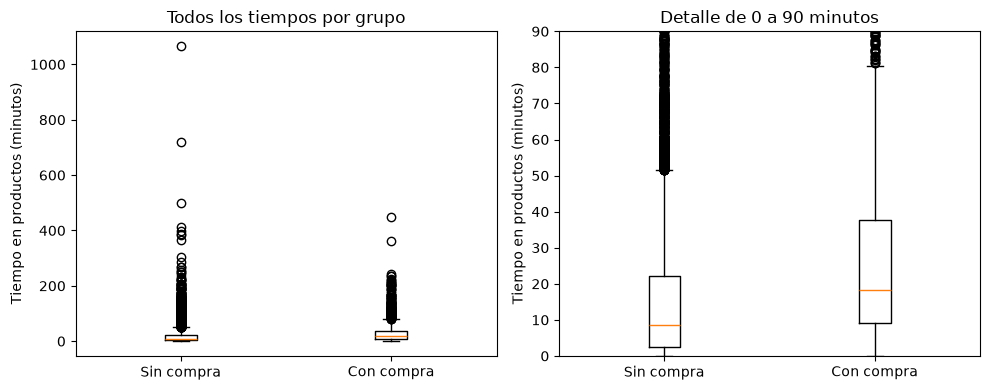

In [16]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.boxplot([tiempo_sin_compra, tiempo_con_compra], tick_labels=["Sin compra", "Con compra"])
plt.title("Todos los tiempos por grupo")
plt.ylabel("Tiempo en productos (minutos)")

plt.subplot(1, 2, 2)
plt.boxplot([tiempo_sin_compra, tiempo_con_compra], tick_labels=["Sin compra", "Con compra"])
plt.ylim(0, 90)
plt.title("Detalle de 0 a 90 minutos")
plt.ylabel("Tiempo en productos (minutos)")

plt.tight_layout()
plt.savefig("resultados/02_boxplot.png", dpi=180)
plt.show()

La caja del grupo con compra está más arriba: su mediana y sus cuartiles son mayores. También hay mucha variación y los grupos se superponen. Un tiempo alto no asegura una compra.

**Antes de continuar:** explicar con sus palabras por qué un tiempo muy alto mueve más la media que la mediana. Revisar también qué parte del gráfico corresponde a una ampliación.

## Paso 9 Estimar las medias con intervalos de confianza

La media de cada grupo es nuestra **estimación puntual**: un solo número. El **intervalo de confianza** agrega un rango para mostrar la incertidumbre al estimar la media de sesiones comparables.

Seguimos el ejemplo de una media con desviación poblacional desconocida del tutorial `python`. Usamos un intervalo t del **95%**. El **error estándar** se calcula como desviación estándar dividida por la raíz de la cantidad de sesiones. Describe la incertidumbre de la media, mientras que la desviación estándar describe la variación de las sesiones.

Primero calculamos el grupo sin compra. `len()` entrega la cantidad de datos y `np.sqrt()` calcula una raíz cuadrada. La opción `df` de `stats.t.interval` indica grados de libertad; en este cálculo es cantidad menos uno, y no corresponde a nuestra tabla llamada `df`.

In [17]:
n_sin_compra = len(tiempo_sin_compra)
media_sin_compra = tiempo_sin_compra.mean()
desviacion_sin_compra = tiempo_sin_compra.std()
error_sin_compra = desviacion_sin_compra / np.sqrt(n_sin_compra)

ic_sin_compra = stats.t.interval(
    confidence=0.95,
    df=n_sin_compra - 1,
    loc=media_sin_compra,
    scale=error_sin_compra
)
print(f"Media sin compra: {media_sin_compra:.2f} minutos")
print(f"IC del 95%: {ic_sin_compra[0]:.2f} a {ic_sin_compra[1]:.2f} minutos")

Media sin compra: 17.86 minutos
IC del 95%: 17.24 a 18.48 minutos


Repetimos los mismos pasos para el grupo con compra. `loc` es el centro del intervalo y `scale`, el error estándar. En cada resultado, `[0]` es el límite inferior y `[1]`, el superior.

In [18]:
n_con_compra = len(tiempo_con_compra)
media_con_compra = tiempo_con_compra.mean()
desviacion_con_compra = tiempo_con_compra.std()
error_con_compra = desviacion_con_compra / np.sqrt(n_con_compra)

ic_con_compra = stats.t.interval(
    confidence=0.95,
    df=n_con_compra - 1,
    loc=media_con_compra,
    scale=error_con_compra
)
print(f"Media con compra: {media_con_compra:.2f} minutos")
print(f"IC del 95%: {ic_con_compra[0]:.2f} a {ic_con_compra[1]:.2f} minutos")

Media con compra: 30.99 minutos
IC del 95%: 29.21 a 32.78 minutos


Los intervalos son **17,24 a 18,48 minutos sin compra** y **29,21 a 32,78 con compra**. Se refieren a las **medias**, no al rango donde están el 95% de las sesiones.

El 95% describe el procedimiento: si repitiéramos el muestreo y el cálculo muchas veces, aproximadamente 95 de cada 100 intervalos cubrirían la media poblacional, bajo los supuestos. No significa que el 95% de los clientes tenga esos tiempos.

## Paso 10 Comparar las medias con la prueba t de Welch

Queremos saber si la diferencia observada aporta evidencia de una diferencia en el tiempo medio. Esta es la prueba de dos grupos independientes que aparece en el **escenario 3 del tutorial `suite`**.

- **Hipótesis nula, H0:** las medias de ambos grupos son iguales.
- **Hipótesis alternativa, H1:** las medias son distintas.
- **Nivel de significancia, alfa:** 0,05.
- **Bilateral:** permite detectar una diferencia en cualquiera de las dos direcciones.

Usamos Welch porque comparamos una variable numérica entre dos grupos y no suponemos que tengan la misma varianza. `equal_var=False` expresa esa decisión.

**Supuestos y límites:** tratamos las sesiones como independientes, de acuerdo con la descripción de usuarios distintos del dataset. Los gráficos muestran asimetría y valores extremos, por lo que no afirmamos que los tiempos sean normales. Los grupos son grandes (1.710 y 9.387), lo que permite una aproximación para comparar las medias; los intervalos y la prueba siguen siendo aproximados. El tamaño grande no vuelve normales los tiempos ni garantiza que representen a todas las tiendas.

In [19]:
alfa = 0.05
resultado_welch = stats.ttest_ind(
    tiempo_con_compra,
    tiempo_sin_compra,
    equal_var=False,
    alternative="two-sided"
)

print(f"Estadístico t: {resultado_welch.statistic:.4f}")
print(f"Valor p: {resultado_welch.pvalue:.3e}")

if resultado_welch.pvalue < alfa:
    print("Rechazamos H0: hay evidencia de una diferencia entre las medias.")
else:
    print("No rechazamos H0: no hay evidencia suficiente de una diferencia.")

Estadístico t: 13.6302
Valor p: 1.257e-40
Rechazamos H0: hay evidencia de una diferencia entre las medias.


El **estadístico t** compara la diferencia de medias con su error estándar. El **valor p** indica qué tan compatible sería una diferencia como esta, o más extrema, con H0 y los supuestos de la prueba.

Aquí `1.257e-40` significa aproximadamente **1,257 × 10⁻⁴⁰**, un número muy pequeño, menor que 0,05; no es cero. Rechazamos la igualdad de medias. El valor p no es la probabilidad de que H0 sea verdadera y tampoco mide cuán grande es la diferencia. Para eso calculamos los minutos de diferencia.

## Paso 11 Medir la diferencia y su intervalo

Restamos **media con compra menos media sin compra**. Un resultado positivo indica mayor tiempo medio con compra.

`confidence_interval()` obtiene de la misma prueba el intervalo para la **diferencia de medias**. Es el mismo objetivo que el intervalo de dos grupos del tutorial `python`; usamos la función para evitar escribir una fórmula larga de grados de libertad.

In [20]:
diferencia_medias = media_con_compra - media_sin_compra
ic_diferencia = resultado_welch.confidence_interval(confidence_level=0.95)

print(f"Diferencia de medias: {diferencia_medias:.2f} minutos")
print(f"IC del 95%: {ic_diferencia.low:.2f} a {ic_diferencia.high:.2f} minutos")

Diferencia de medias: 13.13 minutos
IC del 95%: 11.24 a 15.02 minutos


La diferencia estimada es **13,13 minutos** y su IC del 95% va de **11,24 a 15,02 minutos**. Todo el intervalo está por encima de cero. Esto es coherente con la decisión de la prueba: las sesiones con compra tienen mayor tiempo medio en esta comparación.

El intervalo de la diferencia no se obtiene restando directamente los extremos de los dos intervalos individuales. La prueba calcula la incertidumbre de la diferencia usando ambos grupos.

## Paso 12 Responder la pregunta y revisar el informe

**Respuesta:** en las 11.097 sesiones con tiempo disponible, el promedio es mayor en las sesiones con compra: **30,99 minutos**, frente a **17,86 sin compra**. La diferencia estimada es **13,13 minutos**, con IC del 95% de **11,24 a 15,02**. La prueba de Welch aporta evidencia de una diferencia de medias.

**Qué puede hacer la tienda con este resultado:** revisar cómo se buscan y comparan los productos. El análisis puede ayudar a formular nuevas preguntas sobre la navegación, pero no demuestra que alargar una visita aumente las compras.

**Límites:** se trata de un sitio y un período; no conocemos un muestreo representativo de todas las tiendas. No hemos separado el efecto de cantidad de páginas, mes o tipo de visitante. Conservamos tiempos extremos y filas idénticas; no hay un identificador para confirmar duplicados. Los faltantes fueron creados al azar para el curso y no necesariamente representan lo que ocurriría en una tienda real.

**Para comprobar que lo entendemos, cada integrante debe poder explicar:**

1. Qué representa una fila y qué significa `Revenue`.
2. Por qué el análisis del tiempo usa 11.097 sesiones y los conteos de compra usan 12.330.
3. Por qué media y mediana son distintas.
4. Qué muestran las cajas y por qué ampliamos una parte de los gráficos.
5. Qué dicen H0, el valor p y el intervalo de la diferencia.
6. Por qué una diferencia entre grupos no demuestra causalidad.

Revisar luego `informe_formativa_1.docx`. La entrega en Canvas requiere PDF; se exportará desde el Word aprobado. También queda la participación del equipo en el foro.

## Referencias

1. Sakar, C. y Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI. https://doi.org/10.24432/C5F88Q
2. Köktürk Güzel, B. E. y Ünay, D. (2021). *Predicting Purchase Interest of Online Shoppers Using Boosting Algorithms*. Natural & Applied Sciences Journal, 4(2), 32–37. Tabla 1, p. 35, para las unidades de duración. https://doi.org/10.38061/idunas.848233
3. Universidad Andrés Bello. Semana 1: `f2_s01_tutorial_workflow.ipynb`, `f2_s01_tutorial_python.ipynb`, `f2_s01_tutorial_suite.ipynb` y `f2_s01_tutorial_notebook.ipynb`.
4. Universidad Andrés Bello. *Bases de Datos Disponibles*, p. 3: preparación de faltantes; p. 6: dataset seleccionado.
5. Universidad Andrés Bello. *Formativa 1. Informe 1*: enunciado y rúbrica en Canvas.
6. SciPy. `scipy.stats.ttest_ind`, prueba de Welch e intervalo de la diferencia. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html